# 순서와 합성

**이 노트북에서 할 일**

1. 이름표 A와 B마다 훅을 세 종류씩, 모두 여섯 개 만듭니다.
2. A 다음 B 순서로 등록하고, 훅이 실행된 순서를 읽습니다.
3. 등록 순서를 B 다음 A로 바꿔 실행 순서가 어떻게 바뀌는지 비교합니다.

**준비물** — `.env` 파일의 `OPENAI_API_KEY`. 데이터 파일은 없습니다. 모델 호출은 2번이고 실행 시간은 1분 이내입니다. 예상 비용은 0.01달러 미만입니다.

## 오늘 볼 그림

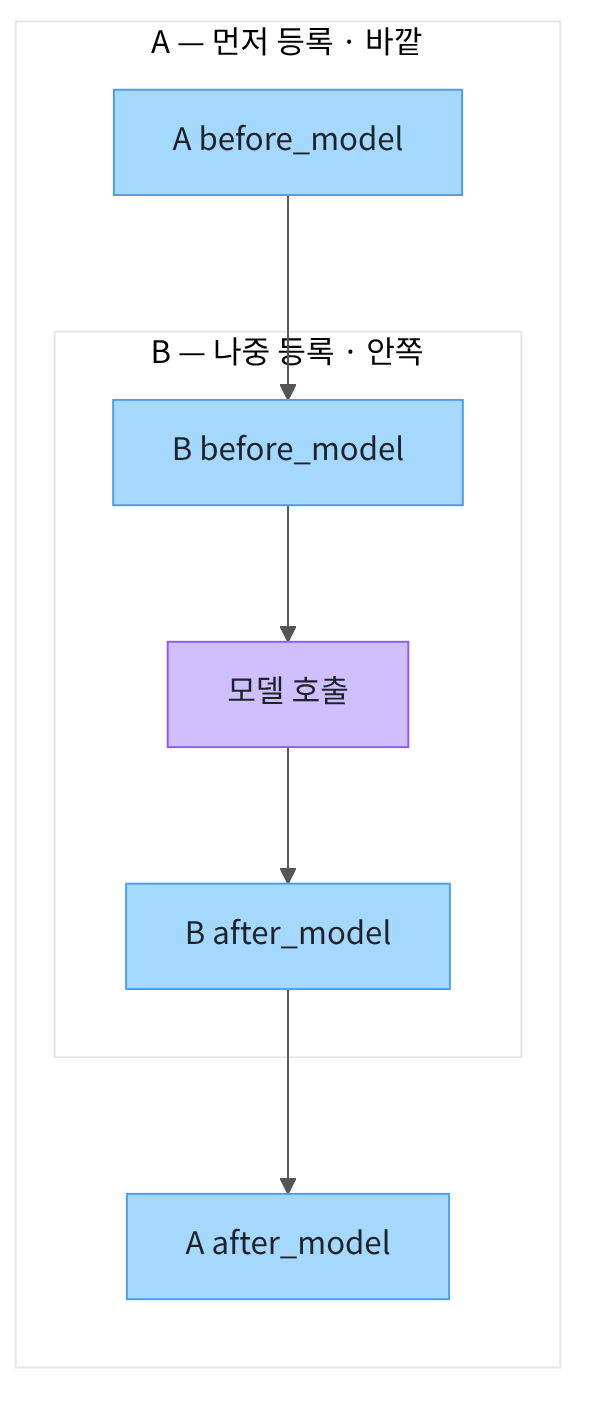

바깥 칸이 먼저 등록한 A, 안쪽 칸이 B입니다. 들어갈 때는 A 다음 B, 나올 때는 B 다음 A 순서입니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11


이번 절에서 쓰는 이름을 불러옵니다. 01절과 같은 훅 데코레이터를 씁니다.

In [2]:
# 에이전트·훅·모델을 만드는 도구를 불러옵니다
from collections.abc import Callable

from langchain.agents import create_agent
from langchain.agents.middleware import AgentState, ModelRequest, ModelResponse, Runtime
from langchain.agents.middleware import after_model, before_model, wrap_model_call
from langchain.chat_models import init_chat_model

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다. 01절과 같은 설정입니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-15에 이 모델로 실행한 결과입니다.

## 2. 이름표 붙은 훅 만들기

04절에서는 재시도 미들웨어를 기록 훅보다 앞에 두어 시도 3번을 모두 기록했습니다.
이번에는 훅을 여러 개 등록했을 때의 순서 규칙을 확인합니다. 실행 순서를 적을 빈 목록부터 만듭니다.

In [5]:
# 훅이 실행된 순서를 적을 빈 목록을 만듭니다
order = []
print("기록 개수:", len(order))

기록 개수: 0


**결과 읽기** — 기록 개수는 `0`입니다.

이름표 A가 붙은 훅 세 개를 만듭니다. 먼저 모델을 부르기 직전에 실행되는 훅입니다.
데코레이터로 만든 훅은 하나가 미들웨어 하나입니다. 이 노트북에서는 이름표가 같은 세 개를 묶어 「미들웨어 A」라고 부릅니다.

In [6]:
# A: 모델을 부르기 직전에 실행되는 훅
@before_model
def a_before(state: AgentState, runtime: Runtime) -> None:
    order.append("A before_model")

이름표 A의 두 번째 훅은 모델 호출을 감쌉니다.

In [7]:
# A: 모델 호출을 앞뒤로 감싸는 훅
@wrap_model_call
def a_wrap(request: ModelRequest, handler: Callable) -> ModelResponse:
    order.append("A wrap 시작")
    response = handler(request)
    order.append("A wrap 끝")
    return response

이름표 A의 세 번째 훅은 모델 응답을 받은 직후 실행됩니다.

In [8]:
# A: 모델 응답을 받은 직후 실행되는 훅
@after_model
def a_after(state: AgentState, runtime: Runtime) -> None:
    order.append("A after_model")

이름표 B가 붙은 훅 세 개도 같은 모양으로 만듭니다.

In [9]:
# B: 모델을 부르기 직전에 실행되는 훅
@before_model
def b_before(state: AgentState, runtime: Runtime) -> None:
    order.append("B before_model")

이름표 B의 감싸기형 훅입니다.

In [10]:
# B: 모델 호출을 앞뒤로 감싸는 훅
@wrap_model_call
def b_wrap(request: ModelRequest, handler: Callable) -> ModelResponse:
    order.append("B wrap 시작")
    response = handler(request)
    order.append("B wrap 끝")
    return response

이름표 B의 마지막 훅입니다.

In [11]:
# B: 모델 응답을 받은 직후 실행되는 훅
@after_model
def b_after(state: AgentState, runtime: Runtime) -> None:
    order.append("B after_model")

출력은 없습니다.

## 3. A 다음 B 순서로 등록하기

이름표 A의 훅 세 개를 먼저, 이름표 B의 훅 세 개를 나중에 목록에 넣습니다. 도구 없이 질문 하나를 보내므로 모델은 1번 호출됩니다.
반복문에 쓴 `enumerate(order, start=1)` 함수는 기록마다 1부터 시작하는 번호를 붙여 줍니다.

In [12]:
# A 다음 B 순서로 등록하고 질문 하나를 보냅니다
a_then_b = [a_before, a_wrap, a_after, b_before, b_wrap, b_after]
agent = create_agent(model, tools=[], middleware=a_then_b)
agent.invoke({"messages": [{"role": "user", "content": "한 문장으로 인사해 주세요."}]})
for number, name in enumerate(order, start=1):
    print(number, name)

1 A before_model
2 B before_model
3 A wrap 시작
4 B wrap 시작
5 B wrap 끝
6 A wrap 끝
7 B after_model
8 A after_model


**결과 읽기** — 1~2번은 `A before_model` 다음 `B before_model`입니다. 들어가는 훅은 등록 순서대로 실행됩니다.

3~6번은 `A wrap 시작`, `B wrap 시작`, `B wrap 끝`, `A wrap 끝`입니다. 미들웨어 A가 B를 감싸고, B가 모델을 감쌉니다.

7~8번은 `B after_model` 다음 `A after_model`입니다. 나오는 훅은 등록 순서의 반대로 실행됩니다.

목록에서는 A의 감싸기 훅이 B의 before_model 훅보다 앞에 있습니다. 그래도 2번이 B before_model, 3번이 A wrap 시작입니다.
종류가 다른 훅은 등록 순서와 상관없이 before → wrap → after 순서로 실행됐습니다.

In [13]:
# 실행 순서가 규칙대로인지 확인하고 기록을 비웁니다
expected = [
    "A before_model", "B before_model",
    "A wrap 시작", "B wrap 시작", "B wrap 끝", "A wrap 끝",
    "B after_model", "A after_model",
]
print("규칙과 같은가:", order == expected)
assert order == expected
order.clear()

규칙과 같은가: True


**결과 읽기** — 규칙과 같은지 확인한 결과가 `True`입니다.

## 4. 값 하나 바꿔 보기 — B 다음 A

등록 순서를 B 먼저로 바꿉니다. 실행 전에 예상해 봅니다. 들어가는 before_model 훅은 B가 먼저, 나오는 after_model 훅은 A가 먼저일 것입니다.

In [14]:
# B 다음 A 순서로 등록하고 같은 질문을 보냅니다
b_then_a = [b_before, b_wrap, b_after, a_before, a_wrap, a_after]
agent = create_agent(model, tools=[], middleware=b_then_a)
agent.invoke({"messages": [{"role": "user", "content": "한 문장으로 인사해 주세요."}]})
for number, name in enumerate(order, start=1):
    print(number, name)

1 B before_model
2 A before_model
3 B wrap 시작
4 A wrap 시작
5 A wrap 끝
6 B wrap 끝
7 A after_model
8 B after_model


**결과 읽기** — 이번에는 1번이 `B before_model`이고 마지막 8번이 `B after_model`입니다. 바깥에서 감싸는 쪽도 B로 바뀌었습니다.

## 정리

- 들어가는 훅(before_model)은 등록 순서대로, 나오는 훅(after_model)은 반대 순서로 실행됩니다.
- 감싸기형 훅은 먼저 등록한 것이 바깥에서 감쌉니다.
- 종류가 다른 훅은 등록 순서와 상관없이 before → wrap → after 순서로 실행됐습니다.